# GPU-Accelerated First Response Planning for the 2020 California Lightning Wildfires

_November, 2026_

When a natural disaster strikes, the first few hours are key. First responders often have to quickly map where help is needed and how to route responders and equipment quickly to contain damage, while the scenario changes by the hour. Doing that quickly takes two things. The first is geospatial data that describes the ground, such as roads, stations and water sources. The second is optimization fast enough to turn that data into a plan while the situation keeps changing.

This notebook shows one such example workflow on one GPU, using the [August 2020 California lightning wildfires](https://en.wikipedia.org/wiki/August_2020_California_lightning_wildfires) as the case. Dry lightning started hundreds of fires across Northern California, and from 15 to 21 August, 364 new fires were reported in the region. Most were far from hydrants, and a typical fire engine's tank runs dry in minutes. Keeping engines supplied is the job of water tenders, trucks that fill up at hydrants, lakes and rivers and shuttle water to the engines on the fire line. Deciding where each tender goes, and in what order, is a vehicle routing problem. For a week of fires it is a significant challenge which involves thousands of stops, a deadline on every delivery, limited tank space and a rest for every crew every night.

The GPU runs the data preparation, the model training and the route optimization. [cuDF](https://docs.nvidia.com/cudf/latest/) and [XGBoost](https://xgboost.readthedocs.io/) prepare five years of fire records and train a model to predict which new fires are likely to grow. OpenStreetMap supplies the roads, fire stations and water, and estimated drive times. [NVIDIA cuOpt](https://docs.nvidia.com/cuopt/user-guide/latest/introduction.html) then searches many candidate routes at once on the GPU. It returns a plan for the whole week, which is then visualized on a map.

This notebook uses publicly available data from that week to answer one question. Where should each water tender go, and when, to keep the engines at the most important fires supplied all week? It works in seven steps.

1. Real fires. 364 fires reported in Northern California from 15 to 21 August 2020. Each appears at 8 AM on the day it was reported.
2. XGBoost ranks them into three tiers. The tier sets how many engines a fire gets and how much its water counts.
3. One engine per fire station. Each new fire gets its closest free engines. An engine is free again once it is back from its last fire.
4. Arrive later, fight longer. The fire grows while an engine drives, so it takes as long to knock down as the engine took to get there (at least 15 minutes).
5. A tank lasts 20 minutes, so every engine needs a refill every 20 minutes while it works.
6. 80 water tenders carry five refills each. Each fire has a fill site, its nearest water by road, which can be a hydrant or a lake or river next to a road. Every tender rests at least 8 hours overnight, between 6 PM and 10 AM.
7. cuOpt plans every tender's week to deliver the most water, on time, to the fires that matter most. OR-Tools on the CPU solves the same problem for comparison.

```{note}
This is an illustrative example with a lot of assumptions, not a realistic operational tool. The fleet and water capacity numbers are round assumptions along with the fact that all fires that happened in that week already known when creating the plan.
```

## Before You Begin

### What this notebook uses

Three libraries do the GPU work.

- [cuDF](https://docs.nvidia.com/cudf/latest/) is a pandas-like DataFrame library that runs on the GPU. It loads and cleans 385,000 historical fire records.
- [XGBoost](https://xgboost.readthedocs.io/) trains a gradient-boosted tree model on the GPU to rank the fires by how large they are likely to grow.
- [cuOpt](https://docs.nvidia.com/cuopt/user-guide/latest/introduction.html) solves the routing problem on the GPU.

### New to routing?

A routing solver takes vehicles and orders, plus the travel time between every pair of places. Here the vehicles are water tenders and the orders are refills to deliver. The solver decides which vehicle serves which orders, and in what sequence. Rules such as "fill before you deliver", "never carry more than five refills" and "arrive before the engine runs dry" become constraints the plan must satisfy. When there isn't time to serve everything, each order can carry a prize, and the solver collects as much prize as it can. The table in Stage 4 maps each part of this story to the cuOpt call that models it.

### Running this notebook on Brev

Everything below runs on a single machine with one NVIDIA GPU.

````{docref} /cloud/nvidia/brev
Follow the instructions in [NVIDIA Brev](../../cloud/nvidia/brev) to launch an instance. It needs the following.

- One GPU. An NVIDIA L4 (24 GB) or similar. The notebook uses only a few GB of GPU memory.
- At least 64 GB of RAM. The travel-time step keeps the shortest paths for about 1,700 locations in memory, about 11 GB.
- About 10 GB of free disk for the packages and the 1.7 GB of data.
- VM Mode with Jupyter as the runtime.

The instance type used for every number in this notebook is `g2-standard-16:nvidia-l4:1` on GCP. Open Jupyter from the Brev console, or forward it with `brev port-forward <instance> -p 8888:8888`.
````

Any other Linux machine with an NVIDIA GPU works too, for example a [GCP Compute Engine](../../cloud/gcp/compute-engine) VM. It needs a driver that supports CUDA 13 (580 or newer) and Python 3.12 or newer.

### How to size the machine

Every timing in this notebook was measured on a GCP `g2-standard-16`. It has one NVIDIA L4 with 24 GB of memory, 16 vCPUs and 64 GB of RAM, and costs about $1.37 per hour. cuOpt and OR-Tools run on the same machine, so their results compare directly. The whole notebook runs in about 13 minutes.

### Creating the environment

The Jupyter kernel on a Brev instance already runs Python 3.12, so the install cell below works as is. Elsewhere, start from a fresh Python 3.12 environment.

### Install the Packages

Run this cell to install cuDF, cuOpt and the other packages. The `-cu13` packages match CUDA 13 drivers.

In [1]:
%pip install --quiet --extra-index-url=https://pypi.nvidia.com \
    "cudf-cu13==26.10.*" "cuopt-cu13==26.10.*" \
    "xgboost>=3.4" ortools scipy osmium folium matplotlib pandas pyarrow scikit-learn requests

Note: you may need to restart the kernel to use updated packages.


### Import the Libraries and Set the Scenario

The scenario is the week of 15 to 21 August 2020. Downloads go to a `data/` folder next to the notebook.

In [2]:
import json
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cudf
import folium
import matplotlib.pyplot as plt
import numpy as np
import osmium
import pandas as pd
import requests
import xgboost as xgb
from branca.element import Figure, MacroElement
from cuopt import routing
from cuopt.distance_engine import WaypointMatrix
from folium.elements import JSCSSMixin
from jinja2 import Template
from ortools.constraint_solver import pywrapcp, routing_enums_pb2
from scipy import sparse
from scipy.sparse.csgraph import connected_components, dijkstra
from scipy.spatial import cKDTree
from sklearn.metrics import roc_auc_score

DATA = Path("data")
DATA.mkdir(exist_ok=True)
SEED = 17
DAYS = ("2020-08-15", "2020-08-21")

## Stage 1 · Rank the Fires

The first stage predicts which fires are likely to grow large, so the routing can send water to them first.

### 1. Download the Fire Records

The fire records come from the US Forest Service [Fire Program Analysis fire-occurrence database](https://doi.org/10.2737/RDS-2013-0009.6) (Short, 2022). The [FPA FOD-Attributes](https://zenodo.org/records/8381129) dataset (Pourmohamad et al., 2024, CC BY 4.0) adds weather, fuel moisture, terrain and access details to each fire. There is one CSV per year, about 1 GB in total. The model trains on 2015 to 2019 and replays 2020. Run this cell to download the six files in parallel.

```{tip}
Zenodo sometimes refuses downloads from cloud IP ranges with HTTP 403. If that happens, download the six CSVs on your own machine and copy them into the `data/` folder next to this notebook. The cell skips files that already exist.
```

In [3]:
ZENODO = "https://zenodo.org/records/8381129/files/{year}_FPA_FOD_cons.csv?download=1"
YEARS = range(2015, 2021)


def download(url, path):
    if path.exists():
        return path
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        tmp = path.with_suffix(".part")
        with open(tmp, "wb") as f:
            for chunk in r.iter_content(chunk_size=1 << 20):
                f.write(chunk)
        tmp.rename(path)
    return path


fire_paths = {y: DATA / f"{y}_FPA_FOD_cons.csv" for y in YEARS}
with ThreadPoolExecutor(max_workers=6) as pool:
    list(pool.map(lambda y: download(ZENODO.format(year=y), fire_paths[y]), YEARS))
print(
    f"{sum(p.stat().st_size for p in fire_paths.values()) / 1e6:,.0f} MB of fire records"
)

1,050 MB of fire records


### 2. Choose What the Model May Use

The model may only use what a dispatcher would know when a fire is reported. That covers four kinds of data.

- The day's weather and fuel moisture.
- Terrain and vegetation.
- Population.
- Distance to roads and fire stations.

Columns that describe how a fire turned out, such as containment dates or incident names, are left out.

`prep` loads and cleans the records with cuDF, so the work runs on the GPU. cuDF reads like pandas, so the code should look familiar.

In [4]:
WEATHER = [
    "pr",
    "tmmx",
    "rmin",
    "vs",
    "fm100",
    "fm1000",
    "bi",
    "erc",
    "vpd",
    "erc_5D_mean",
    "vs_5D_max",
    "fm100_5D_min",
    "vpd_5D_max",
]
SITE = [
    "DISCOVERY_DOY",
    "LATITUDE",
    "LONGITUDE",
    "Elevation",
    "Slope",
    "TPI",
    "TRI",
    "EVH",
    "MOD_NDVI_12m",
    "NDVI-1day",
    "Aridity_index",
    "Population",
    "road_county_dis",
    "road_US_dis",
    "road_state_dis",
    "No_FireStation_5.0km",
    "No_FireStation_20.0km",
    "GACC_PL",
    "GHM",
]
CATEGORICAL = ["NWCG_GENERAL_CAUSE", "OWNER_DESCR"]
FEATURES = WEATHER + SITE + CATEGORICAL
META = [
    "FOD_ID",
    "FIRE_SIZE",
    "STATE",
    "GACCAbbrev",
    "DISCOVERY_DATE",
    "FIRE_NAME",
    "COMPLEX_NAME",
]


def prep(paths):
    """Load and clean fire records on the GPU."""
    df = cudf.concat(
        [
            cudf.read_csv(
                p,
                usecols=FEATURES + META,
                dtype={"COMPLEX_NAME": "str", "GACCAbbrev": "str"},
            )
            for p in paths
        ],
        ignore_index=True,
    )
    for c in WEATHER + SITE:
        df[c] = cudf.to_numeric(df[c], errors="coerce").astype("float32")
    for c in CATEGORICAL:
        df[c] = df[c].astype("category")
    df["log_acres"] = np.log10(df["FIRE_SIZE"].clip(lower=0.01)).astype("float32")
    return df

### 3. Load and Clean Five Years of Fires

Run this cell to load and clean the 2015 to 2019 records, about 385,000 fires, on the GPU.

In [5]:
train = prep([fire_paths[y] for y in range(2015, 2020)])
print(f"{len(train):,} training fires")

384,958 training fires


### 4. Prepare the Categories and Pick the Week's Fires

XGBoost reads the two text columns (cause and land owner) as integer codes, which the training years and 2020 share. This cell also selects the fires reported in Northern California during the week.

In [6]:
test = prep([fire_paths[2020]])
for c in CATEGORICAL:
    cats = (
        train[c]
        .cat.categories.to_pandas()
        .union(test[c].cat.categories.to_pandas())
        .tolist()
    )
    for df in (train, test):
        codes = df[c].cat.set_categories(cats).cat.codes.astype("float32")
        df[c] = codes.where(codes >= 0)

fires = test.to_pandas()
day = pd.to_datetime(fires.DISCOVERY_DATE)
fires = fires[
    (fires.STATE == "CA")
    & (fires.GACCAbbrev == "ONCC")
    & (day >= DAYS[0])
    & (day <= DAYS[1])
].reset_index(drop=True)
print(
    f"{len(fires)} fires reported in Northern California from {DAYS[0]} to {DAYS[1]}, "
    f"{(fires.FIRE_SIZE >= 100).sum()} of which grew past 100 acres"
)

364 fires reported in Northern California from 2020-08-15 to 2020-08-21, 47 of which grew past 100 acres


### 5. Train XGBoost on the GPU

One XGBoost regression predicts each fire's final size, in log acres. It trains on the GPU, straight from the cuDF table.

In [7]:
params = dict(
    tree_method="hist",
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    enable_categorical=True,
    feature_types=["q"] * len(WEATHER + SITE) + ["c"] * len(CATEGORICAL),
    random_state=0,
)
model = xgb.XGBRegressor(**params, device="cuda").fit(train[FEATURES], train.log_acres)

### 6. Check the Ranking

Exact size is hard to predict when a fire is first reported, and this model is not a forecast. What it gives is a ranking of which fires are most likely to grow large. Run this cell to see how many of the fires that really passed 100 acres landed in the model's top 20%. The AUC measures how well the ranking separates large fires from small ones, where 0.5 is a coin flip and 1.0 is perfect.

In [8]:
fires["score"] = model.predict(cudf.from_pandas(fires[FEATURES]))
big = fires.FIRE_SIZE >= 100
top = fires.nlargest(round(len(fires) * 0.2), "score")
print(f"AUC for fires that passed 100 acres: {roc_auc_score(big, fires.score):.2f}")
print(
    f"Fires that passed 100 acres in the top 20%: {(top.FIRE_SIZE >= 100).sum()} of {big.sum()}"
)

AUC for fires that passed 100 acres: 0.79
Fires that passed 100 acres in the top 20%: 24 of 47


### 7. Turn the Ranking into Tiers

The tier is the only thing the rest of the notebook takes from the model.

| Tier | Share of fires | Engines sent | Value of each refill |
|---|---|---|---|
| High | top 20% | 3 | 3 |
| Medium | next 30% | 2 | 2 |
| Low | bottom 50% | 1 | 1 |

The shares, engine counts and refill values are assumptions, round numbers chosen for this example rather than any agency's policy. Change them in `TIERS`. What matters is that a fire likely to grow large gets more engines, and its water counts for more.

In [9]:
TIERS = pd.DataFrame(
    {"engines": [3, 2, 1], "value": [3.0, 2.0, 1.0]}, index=["high", "medium", "low"]
)
rank = fires.score.rank(ascending=False, method="first")
fires["tier"] = np.where(
    rank <= round(len(fires) * 0.2),
    "high",
    np.where(rank <= round(len(fires) * 0.5), "medium", "low"),
)
fires = fires.join(TIERS, on="tier")
fires.tier.value_counts()

tier
low       182
medium    109
high       73
Name: count, dtype: int64

## Stage 2 · Map the Roads, Stations and Water

Routing needs real travel times, so this stage builds a road network for Northern California from OpenStreetMap and finds every fire station and water source on it.

### 1. Download the OpenStreetMap Extract

[Geofabrik](https://download.geofabrik.de/north-america/us/california/norcal.html) publishes daily OpenStreetMap extracts. The Northern California file is about 650 MB. OpenStreetMap data is © OpenStreetMap contributors, available under the [Open Database License](https://www.openstreetmap.org/copyright).

In [10]:
PBF = DATA / "norcal-latest.osm.pbf"
download(
    "https://download.geofabrik.de/north-america/us/california/norcal-latest.osm.pbf",
    PBF,
)
print(f"{PBF.stat().st_size / 1e6:,.0f} MB")

656 MB


### 2. Read the Roads

The network keeps the roads a heavy truck would use to cross a region, from motorways down to tertiary roads. Speeds are the [OSRM car profile](https://github.com/Project-OSRM/osrm-backend/blob/746c97c1c8ef7ebeb7acb9b986cf6c4e04f82caf/profiles/car.lua#L175-L195) defaults, or the posted limit where OpenStreetMap has one. The area is the bounding box of the fires, padded by about 50 miles. Run this cell to read the roads. It takes about a minute.

This assumes engines and tenders drive at car speeds. Loaded trucks are slower, especially on mountain roads, so every trip here is a little optimistic.

In [11]:
SPEED_KMH = {
    "motorway": 90,
    "motorway_link": 45,
    "trunk": 85,
    "trunk_link": 40,
    "primary": 65,
    "primary_link": 30,
    "secondary": 55,
    "secondary_link": 25,
    "tertiary": 40,
    "tertiary_link": 20,
}
LAT0, LAT1 = fires.LATITUDE.min() - 0.73, fires.LATITUDE.max() + 0.73
LON0, LON1 = fires.LONGITUDE.min() - 0.95, fires.LONGITUDE.max() + 0.95


def in_box(lat, lon):
    return (lat >= LAT0) & (lat <= LAT1) & (lon >= LON0) & (lon <= LON1)


def haversine_km(lat1, lon1, lat2, lon2):
    p = np.pi / 180
    h = (
        np.sin((lat2 - lat1) * p / 2) ** 2
        + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2
    )
    return 12742 * np.arcsin(np.sqrt(h))


def maxspeed_kmh(tag):
    try:
        value, *unit = tag.split()
        return float(value) * (1.609 if unit and unit[0] == "mph" else 1)
    except (AttributeError, ValueError):
        return None


edges, coords = [], {}
reader = (
    osmium.FileProcessor(str(PBF), osmium.osm.NODE | osmium.osm.WAY)
    .with_locations()
    .with_filter(osmium.filter.KeyFilter("highway"))
)
for way in reader:
    if not way.is_way() or way.tags.get("highway") not in SPEED_KMH:
        continue
    nodes = [
        (n.ref, n.location.lat, n.location.lon) for n in way.nodes if n.location.valid()
    ]
    if len(nodes) < 2:
        continue
    ids, lat, lon = map(np.array, zip(*nodes, strict=False))
    if not in_box(lat, lon).any():
        continue
    coords.update(zip(ids, zip(lat, lon, strict=False), strict=False))
    km = haversine_km(lat[:-1], lon[:-1], lat[1:], lon[1:])
    minutes = (
        km
        / (maxspeed_kmh(way.tags.get("maxspeed")) or SPEED_KMH[way.tags["highway"]])
        * 60
    )
    a, b = ids[:-1], ids[1:]
    oneway = way.tags.get("oneway", "no")
    if oneway == "-1":
        a, b = b, a
    edges.append((a, b, minutes))
    if oneway not in ("yes", "true", "1", "-1") and not way.tags["highway"].startswith(
        "motorway"
    ):
        edges.append((b, a, minutes))

src, dst, minutes = (np.concatenate(x) for x in zip(*edges, strict=False))
print(f"{len(coords):,} road nodes, {len(src):,} directed road segments")

1,749,476 road nodes, 2,979,626 directed road segments


### 3. Make the Network Routable

Shortest-path code wants the graph in compressed sparse row (CSR) form. That is three arrays.

- `offsets` says where each node's edges start.
- `indices` says where each edge goes.
- `minutes` says how long each edge takes.

Fragments cut off by the bounding box are dropped by keeping the largest strongly connected component, the part where every node can reach every other.

In [12]:
ids = np.unique(np.concatenate([src, dst]))
u, v = np.searchsorted(ids, src), np.searchsorted(ids, dst)
order = np.lexsort((minutes, v, u))
u, v, minutes = u[order], v[order], minutes[order]
first = np.r_[
    True, (u[1:] != u[:-1]) | (v[1:] != v[:-1])
]  # keep the fastest of parallel segments
u, v, minutes = u[first], v[first], minutes[first]

_, label = connected_components(
    sparse.csr_matrix((minutes, (u, v)), shape=(len(ids),) * 2), connection="strong"
)
keep = label == np.bincount(label).argmax()
new_id = np.cumsum(keep) - 1
mask = keep[u] & keep[v]
u, v, minutes = new_id[u[mask]], new_id[v[mask]], minutes[mask]
n_nodes = int(keep.sum())
order = np.lexsort((v, u))
u, v, minutes = u[order], v[order], minutes[order].astype(np.float32)

offsets = np.zeros(n_nodes + 1, np.int32)
np.cumsum(np.bincount(u, minlength=n_nodes), out=offsets[1:])
indices = v.astype(np.int32)
node_lat, node_lon = np.array([coords[i] for i in ids[keep]]).T
graph = sparse.csr_matrix(
    (minutes.astype(np.float64), indices, offsets), shape=(n_nodes, n_nodes)
)
del edges, coords
print(f"Road graph: {n_nodes:,} nodes, {len(indices):,} edges")

Road graph: 1,738,280 nodes, 2,966,467 edges


### 4. Attach Points to the Roads

Places that are off the network, such as most fires, attach to their nearest road node. The straight-line distance to that node is added at 20 km/h.

The 20 km/h is an assumed speed for the last stretch on dirt roads, tracks and driveways. It applies the same way for every planner.

In [13]:
LAST_MILE_KMH = 20
xy_scale = np.array([111.32 * np.cos(np.radians((LAT0 + LAT1) / 2)), 110.57])
road_tree = cKDTree(np.c_[node_lon, node_lat] * xy_scale)


def snap(lat, lon):
    km, node = road_tree.query(np.c_[lon, lat] * xy_scale)
    return node.astype(np.int32), km / LAST_MILE_KMH * 60  # node, minutes to reach it


fires["node"], fires["last_mile"] = snap(fires.LATITUDE.values, fires.LONGITUDE.values)
print(
    f"Median distance from a fire to the road network: {fires.last_mile.median() / 60 * LAST_MILE_KMH:.1f} km"
)

Median distance from a fire to the road network: 0.4 km


### 5. Find Fire Stations and Hydrants

One pass over the file collects fire stations (`amenity=fire_station`) and the hydrants, water tanks and water towers a tender can fill from. A station is often mapped twice, as a point and as a building, so stations within 150 m are merged. Each station has one engine.

This assumes each mapped fire station has exactly one engine. Real stations hold anywhere from none to several, and OpenStreetMap misses some stations. One engine per station keeps the problem easy to follow.

In [14]:
TAGS = [
    ("amenity", "fire_station"),
    ("emergency", "fire_hydrant"),
    ("emergency", "water_tank"),
    ("man_made", "water_tower"),
]
station_pts, water_pts = [], []
for obj in (
    osmium.FileProcessor(str(PBF))
    .with_locations()
    .with_filter(osmium.filter.TagFilter(*TAGS))
):
    if obj.is_node():
        point = (obj.location.lat, obj.location.lon)
    elif obj.is_way():
        ring = [(n.lat, n.lon) for n in obj.nodes if n.location.valid()]
        if not ring:
            continue
        point = tuple(np.mean(ring, axis=0))
    else:
        continue
    (station_pts if obj.tags.get("amenity") == "fire_station" else water_pts).append(
        point
    )

station_pts = np.array(station_pts)
station_pts = station_pts[in_box(station_pts[:, 0], station_pts[:, 1])]
keep = np.ones(len(station_pts), bool)
for i in range(len(station_pts)):
    if keep[i]:
        near = (
            haversine_km(
                *station_pts[i], station_pts[i + 1 :, 0], station_pts[i + 1 :, 1]
            )
            < 0.15
        )
        keep[i + 1 :][near] = False
stations = pd.DataFrame(station_pts[keep], columns=["lat", "lon"])
stations["node"], stations["last_mile"] = snap(stations.lat.values, stations.lon.values)
water_pts = np.array(water_pts)
water_pts = water_pts[in_box(water_pts[:, 0], water_pts[:, 1])]
print(
    f"{len(stations):,} fire stations (one engine each), {len(water_pts):,} hydrants, tanks and towers"
)

1,306 fire stations (one engine each), 18,610 hydrants, tanks and towers


### 6. Find Drafting Sites on Lakes and Rivers

Most of these fires were far from any hydrant. Tenders can also draft from other water sources, such as from a lake, reservoir, river or canal. A drafting site here is any road point within 100 m of a river or canal, or of a lake, pond or reservoir of at least 10 acres. Smaller ponds are left out. So is water marked seasonal or intermittent, since much of it is dry in August, and so are wastewater ponds. The notebook keeps at most one site per 500 m.

Real drafting needs deep enough water and a spot where a truck can reach it. OpenStreetMap records neither, so the 10-acre minimum and the 100 m distance are assumptions that stand in for them.

In [15]:
DRAFT_M, THIN_M, MIN_ACRES = 100, 500, 10
metres = lambda lat, lon: np.c_[lon, lat] * xy_scale * 1000  # noqa: E731


def acres(ring):
    """Area of a closed ring of (lat, lon) points, by the shoelace formula."""
    x, y = metres(ring[:, 0], ring[:, 1]).T
    return 0.5 * abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1))) / 4046.86


vertices = []
for obj in (
    osmium.FileProcessor(str(PBF))
    .with_locations()
    .with_areas()
    .with_filter(osmium.filter.KeyFilter("natural", "landuse", "waterway"))
):
    tags = obj.tags
    if tags.get("intermittent") in ("yes", "true") or tags.get("seasonal") in (
        "yes",
        "true",
    ):
        continue
    if tags.get("water") in ("intermittent", "wastewater"):
        continue
    if obj.is_area() and (
        tags.get("natural") == "water" or tags.get("landuse") == "reservoir"
    ):
        rings = [
            np.array([(n.lat, n.lon) for n in r if n.location.valid()])
            for r in obj.outer_rings()
        ]
        rings = [r for r in rings if len(r) >= 3]
        river = tags.get("water") in ("river", "canal")
        # rivers and canals count at any size, lakes, ponds and reservoirs from 10 acres
        if river or sum(map(acres, rings)) >= MIN_ACRES:
            for r in rings:
                vertices.extend(map(tuple, r))
    elif obj.is_way() and tags.get("waterway") in ("river", "canal"):
        vertices.extend((n.lat, n.lon) for n in obj.nodes if n.location.valid())
vertices = np.array(vertices)
vertices = vertices[in_box(vertices[:, 0], vertices[:, 1])]

dist_m, _ = cKDTree(metres(vertices[:, 0], vertices[:, 1])).query(
    metres(node_lat, node_lon), distance_upper_bound=DRAFT_M
)
near_water = np.where(np.isfinite(dist_m))[0]
cell = np.floor(metres(node_lat[near_water], node_lon[near_water]) / THIN_M).astype(
    np.int64
)
_, first = np.unique(cell[:, 0] * 10_000_000 + cell[:, 1], return_index=True)
drafting_nodes = near_water[first]

hydrant_nodes, hydrant_last_mile = snap(water_pts[:, 0], water_pts[:, 1])
source_nodes = np.r_[hydrant_nodes, drafting_nodes]
source_last_mile = np.r_[hydrant_last_mile, np.zeros(len(drafting_nodes))]
print(
    f"{len(drafting_nodes):,} drafting sites, {len(source_nodes):,} water sources in all"
)

10,662 drafting sites, 29,272 water sources in all


## Stage 3 · Send the Engines and Work Out the Water

### 1. Compute Drive Times and Dispatch the Engines

cuOpt's `WaypointMatrix` computes drive times between every station and every fire over the road graph. It runs one shortest-path search per location and keeps the paths so routes can be drawn later.

Times are minutes from midnight on 15 August, and each fire appears at 8 AM on the day it was reported. Fires are handled in the order they appear, and within a day by model rank. Each fire gets its closest free engines. An engine leaves when the fire appears, or as soon as it is back from its last fire. It works for max(15 minutes, the time from the fire appearing to the engine arriving), then drives home.

This step assumes every fire appears at 8 AM on the day it was reported, since only about half the records have a time of day. The engine's working time stands in for a fire that grows while engines drive to it. The recorded final size isn't used, because a dispatcher doesn't know it yet. Engines don't rest.

In [16]:
targets = np.r_[stations.node.values, fires.node.values].astype(np.int32)
last_mile = np.r_[stations.last_mile.values, fires.last_mile.values]
S = len(stations)
full = WaypointMatrix(offsets, indices, minutes).compute_cost_matrix(targets).to_numpy()
full = full + last_mile[:, None] + last_mile[None, :]
drive, drive_home = (
    full[:S, S:],
    full[S:, :S],
)  # stations to fires and fires to stations, minutes
del full

DAY, KNOCKDOWN_FLOOR = 24 * 60, 15
fires["appear"] = (
    pd.to_datetime(fires.DISCOVERY_DATE) - pd.Timestamp(DAYS[0])
).dt.days * DAY + 8 * 60
free_at = np.zeros(S)
visits = []
for f in np.lexsort((-fires.score.values, fires.appear.values)):
    appear = fires.appear.values[f]
    arrive = np.maximum(free_at, appear) + drive[:, f]
    for s in np.argsort(arrive)[: fires.engines.values[f]]:
        work = max(KNOCKDOWN_FLOOR, arrive[s] - appear)
        visits.append({"station": s, "fire": f, "arrive": arrive[s], "work": work})
        free_at[s] = arrive[s] + work + drive_home[f, s]
visits = pd.DataFrame(visits)
wait = visits.arrive - fires.appear.values[visits.fire]
print(
    f"{len(visits)} engines sent. Time from a fire appearing to an engine arriving: median {wait.median():.0f} min, "
    f"longest {wait.max():.0f} min"
)

619 engines sent. Time from a fire appearing to an engine arriving: median 30 min, longest 206 min


### 2. Count the Refills Each Engine Needs

An engine starts with a full 500-gallon tank and uses about 25 gallons a minute, so a tank lasts 20 minutes. An engine working `w` minutes needs `ceil(w / 20) - 1` refills. Refill `j` must arrive between `(j - 1) x 20` and `j x 20` minutes after the engine does, before the tank runs dry. These refills are the orders the tenders must deliver.

500 gallons and 25 gallons a minute are assumed round numbers for a wildland engine, and every engine uses water at the same rate at every fire. So the water a fire needs comes from how many engines it gets and how long they work, not from how large it grew.

In [17]:
TANK_MIN = 20
refills = []
for v in visits.itertuples():
    for j in range(1, int(np.ceil(v.work / TANK_MIN))):
        refills.append(
            {
                "fire": v.fire,
                "earliest": v.arrive + (j - 1) * TANK_MIN,
                "latest": v.arrive + j * TANK_MIN,
            }
        )
refills = pd.DataFrame(refills)
refills["value"] = fires.value.values[refills.fire]
print(f"{len(refills):,} refills to deliver at {refills.fire.nunique()} fires")

1,269 refills to deliver at 183 fires


## Stage 4 · Plan the Water Tenders with cuOpt

### 1. Assign Fill Sites and Park the Tenders

Each fire gets a designated fill site, its nearest water source by road. Every refill for that fire loads there. That is how rural water shuttles are usually organized, and it keeps the problem the same for every planner.

The fleet is 80 water tenders, parked at randomly chosen fire stations.

- Each carries 2,500 gallons, which is five refills, and starts empty.
- Filling or handing over one refill takes 3 minutes.
- Every tender rests at least 8 hours each night, fully between 6 PM and 10 AM. So a rest starts between 6 PM and 2 AM. It can run longer when a tender has nothing to do.

The fleet size, tank size, handling time and rest length are assumed round numbers. Tenders start at randomly chosen stations, so some start far from the fires. The plan also covers the whole week at once and knows every fire in advance. Tenders are free from midnight on 15 August, so some set off before a fire is reported. A real dispatcher would re-plan as fires come in, as the Future Steps section describes.

In [18]:
N_TENDERS, TENDER_REFILLS, HANDLE_MIN = 80, 5, 3
REST_MIN, NIGHT_FROM, NIGHT_TO = (
    8 * 60,
    18 * 60,
    DAY + 10 * 60,
)  # a rest fits fully in 6 PM to 10 AM
NIGHTS = range(int(refills.latest.max() // DAY) + 1)

need = np.unique(refills.fire)
to_source = (
    dijkstra(graph, indices=fires.node.values[need])[:, source_nodes]
    + source_last_mile[None, :]
)
fill_site = dict(zip(need, source_nodes[to_source.argmin(1)], strict=False))
fill_last_mile = dict(zip(need, source_last_mile[to_source.argmin(1)], strict=False))
tender_station = np.random.default_rng(SEED).choice(S, size=N_TENDERS, replace=False)
used_sites = np.unique(list(fill_site.values()))
print(f"{len(used_sites)} fill sites serve {len(need)} fires")

101 fill sites serve 183 fires


### 2. Compute Drive Times for the Tenders

A second `WaypointMatrix` gives drive times between the tenders' stations, the fill sites and the fires. Location ids list the tenders first, then the fill sites, then the fires.

In [19]:
site_last_mile = [
    min(fill_last_mile[f] for f in need if fill_site[f] == s) for s in used_sites
]
locations = np.r_[
    stations.node.values[tender_station], used_sites, fires.node.values[need]
].astype(np.int32)
loc_last_mile = np.r_[
    stations.last_mile.values[tender_station],
    site_last_mile,
    fires.last_mile.values[need],
]
tender_paths = WaypointMatrix(offsets, indices, minutes)
M = tender_paths.compute_cost_matrix(locations).to_numpy()
M = np.rint(M + loc_last_mile[:, None] + loc_last_mile[None, :]).astype(np.float32)
np.fill_diagonal(M, 0)

site_loc = {s: N_TENDERS + i for i, s in enumerate(used_sites)}
fire_loc = {f: N_TENDERS + len(used_sites) + i for i, f in enumerate(need)}
refills["pick_loc"] = [site_loc[fill_site[f]] for f in refills.fire]
refills["drop_loc"] = [fire_loc[f] for f in refills.fire]
R = len(refills)
print(f"{M.shape[0]} locations, {2 * R:,} stops (a fill and a delivery per refill)")

364 locations, 2,538 stops (a fill and a delivery per refill)


### 3. Build the Routing Model in cuOpt

Each part of the story maps to one cuOpt call.

| In the story | In cuOpt |
|---|---|
| Drive times between places | `add_cost_matrix` and `add_transit_time_matrix` |
| A refill, filled at the fire's fill site and then delivered to the fire | two orders tied together with `set_pickup_delivery_pairs` |
| A tender holds at most five refills | `add_capacity_dimension` with a load of +1 at a fill and -1 at a delivery |
| Deliver before the engine's tank runs dry | `set_order_time_windows` |
| 3 minutes to fill or hand over a refill | `set_order_service_times` |
| Tenders start at their stations and don't need to return | `set_vehicle_locations` and `set_drop_return_trips` |
| A rest every night, between 6 PM and 10 AM | `add_vehicle_break`, once per tender per night, with a start window and a duration |
| Refills at high-tier fires matter more | `set_order_prizes`, with each refill worth its fire's tier value |
| Deliver the most value, then drive the least | `set_objective_function` with a large weight on prizes and a small one on cost |
| How long the solver may search | `SolverSettings.set_time_limit` |

Missing a refill is allowed, but it loses that refill's value. Run this cell to define `cuopt_plan`, which builds the model and returns each tender's timeline of fills, deliveries and rests, with their times.

In [20]:
VALUE_WEIGHT, DRIVE_WEIGHT = 1000.0, 1.0
pickups, deliveries = np.arange(0, 2 * R, 2, dtype=np.int32), np.arange(
    1, 2 * R, 2, dtype=np.int32
)
order_loc = np.ravel(np.c_[refills.pick_loc, refills.drop_loc]).astype(np.int32)
earliest = np.zeros(2 * R, np.int32)
latest = np.repeat(np.floor(refills.latest.to_numpy()).astype(np.int32), 2)
earliest[deliveries] = np.floor(refills.earliest.to_numpy()).astype(np.int32)
load = np.where(np.arange(2 * R) % 2 == 0, 1, -1).astype(np.int32)  # in refills


def cuopt_plan(time_limit):
    dm = routing.DataModel(M.shape[0], N_TENDERS, 2 * R)
    matrix = cudf.DataFrame(M)
    dm.add_cost_matrix(matrix)
    dm.add_transit_time_matrix(matrix)
    dm.set_order_locations(cudf.Series(order_loc))
    dm.set_pickup_delivery_pairs(cudf.Series(pickups), cudf.Series(deliveries))
    dm.add_capacity_dimension(
        "water",
        cudf.Series(load),
        cudf.Series(np.full(N_TENDERS, TENDER_REFILLS, np.int32)),
    )
    dm.set_order_time_windows(cudf.Series(earliest), cudf.Series(latest))
    dm.set_order_service_times(cudf.Series(np.full(2 * R, HANDLE_MIN, np.int32)))
    dm.set_order_prizes(
        cudf.Series(np.repeat(refills.value.values.astype(np.float32), 2))
    )  # equal on each pair
    starts = cudf.Series(np.arange(N_TENDERS, dtype=np.int32))
    dm.set_vehicle_locations(starts, starts)
    dm.set_drop_return_trips(cudf.Series(np.ones(N_TENDERS, bool)))
    anywhere = cudf.Series([], dtype="int32")  # a rest can be taken at any location
    for t in range(N_TENDERS):
        for n in NIGHTS:
            dm.add_vehicle_break(
                t,
                n * DAY + NIGHT_FROM,
                n * DAY + NIGHT_TO - REST_MIN,
                REST_MIN,
                anywhere,
            )
    dm.set_objective_function(
        cudf.Series([routing.Objective.PRIZE, routing.Objective.COST]),
        cudf.Series([VALUE_WEIGHT, DRIVE_WEIGHT], dtype="float32"),
    )
    settings = routing.SolverSettings()
    settings.set_time_limit(time_limit)
    solution = routing.Solve(dm, settings)
    assert solution.get_status() == 0, solution.get_error_message()
    plan = {}
    for t, g in solution.get_route().to_pandas().groupby("truck_id", sort=False):
        stops = []
        for kind, o, stamp, loc in zip(
            g.type, g.route, g.arrival_stamp, g.location, strict=False
        ):
            if kind == "Break":
                stops.append(("rest", int(loc), float(stamp)))
            elif kind in ("Pickup", "Delivery"):
                stops.append(
                    (
                        "fill" if kind == "Pickup" else "drop",
                        int(o) // 2,
                        max(float(stamp), float(earliest[o])),
                    )
                )
        if any(kind != "rest" for kind, _, _ in stops):
            plan[int(t)] = stops
    return plan

### 4. Build the Same Model in OR-Tools

For reference, the same problem also goes to [OR-Tools](https://developers.google.com/optimization/routing), a widely used open source routing solver that runs on the CPU. The model is the same. Refills are pairs added with `AddPickupAndDelivery`, and capacity and time are dimensions. Leaving a refill out costs a penalty equal to its value. Each night's rest is a break interval on the tender's time dimension. Parallel cheapest insertion with guided local search was the strongest OR-Tools setup we tried for this problem.

In [21]:
def ortools_plan(time_limit):
    T = N_TENDERS
    N = (
        1 + T + 2 * R
    )  # node 0 is a dummy end, then tenders, then fill and delivery per refill
    node_loc = np.r_[-1, np.arange(T), order_loc]
    BIG = 10**6
    travel = np.full((N, N), BIG, np.int64)
    travel[1:, 1:] = M[np.ix_(node_loc[1:], node_loc[1:])]
    travel[1 : 1 + T, 1 : 1 + T] = BIG
    travel[1 + T :, 1 : 1 + T] = BIG
    travel[:, 0] = 0
    np.fill_diagonal(travel, 0)
    service = np.r_[np.zeros(1 + T, np.int64), np.full(2 * R, HANDLE_MIN)]
    demand = np.r_[np.zeros(1 + T, np.int64), load]

    manager = pywrapcp.RoutingIndexManager(N, T, list(range(1, T + 1)), [0] * T)
    model = pywrapcp.RoutingModel(manager)
    model.SetArcCostEvaluatorOfAllVehicles(model.RegisterTransitMatrix(travel.tolist()))
    horizon = int(latest.max()) + 2 * DAY
    model.AddDimension(
        model.RegisterTransitMatrix(
            np.minimum(travel + service[:, None], BIG).tolist()
        ),
        horizon,
        horizon,
        True,
        "Time",
    )
    model.AddDimensionWithVehicleCapacity(
        model.RegisterUnaryTransitVector(demand.tolist()),
        0,
        [TENDER_REFILLS] * T,
        True,
        "Water",
    )
    clock, solver = model.GetDimensionOrDie("Time"), model.solver()
    for r in range(R):
        p, d = manager.NodeToIndex(1 + T + 2 * r), manager.NodeToIndex(2 + T + 2 * r)
        model.AddPickupAndDelivery(p, d)
        solver.Add(model.VehicleVar(p) == model.VehicleVar(d))
        solver.Add(clock.CumulVar(p) <= clock.CumulVar(d))
        solver.Add(model.ActiveVar(p) == model.ActiveVar(d))
        clock.CumulVar(d).SetRange(int(earliest[2 * r + 1]), int(latest[2 * r + 1]))
        clock.CumulVar(p).SetRange(0, int(latest[2 * r]))
        model.AddDisjunction([p], 0)
        model.AddDisjunction(
            [d], int(round(refills.value.values[r] * VALUE_WEIGHT / DRIVE_WEIGHT))
        )
    visit = [int(service[manager.IndexToNode(i)]) for i in range(model.Size())]
    for t in range(T):
        rests = [
            solver.FixedDurationIntervalVar(
                n * DAY + NIGHT_FROM,
                n * DAY + NIGHT_TO - REST_MIN,
                REST_MIN,
                False,
                f"rest_{t}_{n}",
            )
            for n in NIGHTS
        ]
        clock.SetBreakIntervalsOfVehicle(rests, t, visit)
    search = pywrapcp.DefaultRoutingSearchParameters()
    search.first_solution_strategy = (
        routing_enums_pb2.FirstSolutionStrategy.PARALLEL_CHEAPEST_INSERTION
    )
    search.local_search_metaheuristic = (
        routing_enums_pb2.LocalSearchMetaheuristic.GUIDED_LOCAL_SEARCH
    )
    search.time_limit.FromSeconds(time_limit)
    solution = model.SolveWithParameters(search)
    plan = {}
    if solution:
        rest_starts = {}
        intervals = solution.IntervalVarContainer()
        for k in range(intervals.Size()):
            e = intervals.Element(k)
            rest_starts.setdefault(int(e.Var().Name().split("_")[1]), []).append(
                float(e.StartValue())
            )
        for t in range(T):
            i, stops = model.Start(t), []
            while not model.IsEnd(i):
                node = manager.IndexToNode(i)
                if node > T:
                    kind = "fill" if (node - T) % 2 else "drop"
                    stops.append(
                        (
                            kind,
                            (node - T - 1) // 2,
                            float(solution.Value(clock.CumulVar(i))),
                        )
                    )
                i = solution.Value(model.NextVar(i))
            if stops:
                plan[t] = sorted(
                    stops + [("rest", None, s) for s in rest_starts.get(t, [])],
                    key=lambda x: x[2],
                )
    return plan

### 5. Check Every Plan the Same Way

The score ignores the value each solver reports. It replays every tender's timeline against the drive times and checks four rules.

- Each stop must be reachable from the one before, including through any rest.
- A tender never carries more than five refills.
- A refill counts only if the same tender filled it first and delivered it inside its window.
- Every tender has at least 8 hours without work inside every night's window. Idle time counts, not only the rests a solver labels.

The score is the share of refill value delivered on time, where each refill is worth its fire's tier value. Breaking any rule counts as a violation.

In [22]:
def score(plan, return_delivered=False):
    """plan: tender -> [(kind, item, start)], kind is fill, drop or rest. For a rest, item is where the tender
    rests, or None when the solver doesn't place rests at a location."""
    pick, drop = refills.pick_loc.values, refills.drop_loc.values
    soon, late = np.floor(refills.earliest.values), np.floor(refills.latest.values)
    delivered, broken = [], 0
    for t, stops in plan.items():
        at, free_from, carried, filled, idle, owed = t, 0.0, 0, set(), [], 0.0
        for kind, item, start in stops:
            if kind == "rest":
                if item is None:
                    idle.append((start, start + REST_MIN))
                    owed += REST_MIN
                    continue
                broken += start + 1e-6 < free_from + M[at, item]
                idle += [(free_from, start - M[at, item]), (start, start + REST_MIN)]
                at, free_from = item, start + REST_MIN
                continue
            loc = pick[item] if kind == "fill" else drop[item]
            broken += start + 1e-6 < free_from + M[at, loc] + owed
            idle.append((free_from, start - M[at, loc] - owed))
            owed = 0.0
            if kind == "fill":
                carried += 1
                filled.add(item)
            else:
                carried -= 1
                on_time = (
                    item in filled and soon[item] - 1e-6 <= start <= late[item] + 1e-6
                )
                if on_time:
                    delivered.append(item)
                broken += not on_time
            broken += carried > TENDER_REFILLS
            at, free_from = loc, start + HANDLE_MIN
        idle.append((free_from, np.inf))
        for n in NIGHTS:
            a, b = n * DAY + NIGHT_FROM, n * DAY + NIGHT_TO
            broken += not any(min(e, b) - max(s, a) >= REST_MIN - 1e-6 for s, e in idle)
    value = refills.value.values[delivered].sum() / refills.value.sum()
    summary = {
        "refills delivered": len(delivered),
        "value delivered (%)": round(100 * value, 1),
        "tenders used": len(plan),
        "rule violations": int(broken),
    }
    return (summary, delivered) if return_delivered else summary

### 6. Compare the Plans

A dispatcher re-plans whenever a new fire is reported, so how soon a good plan arrives matters as much as how good it gets. Run this cell to build cuOpt's plans with budgets of 10, 30 and 60 seconds. For reference, OR-Tools gets the same budgets and one longer run of 4 minutes. 
This cell takes about 8 minutes to run.

In [23]:
plans, results = {}, []
for limit in (10, 30, 60):
    for name, solve in (("cuOpt", cuopt_plan), ("OR-Tools", ortools_plan)):
        start = time.perf_counter()
        plans[name, limit] = solve(limit)
        wall = time.perf_counter() - start
        results.append(
            {
                "solver": name,
                "budget (s)": limit,
                "wall time (s)": round(wall, 1),
                **score(plans[name, limit]),
            }
        )
start = time.perf_counter()  # one longer OR-Tools run, to see when it catches up
plans["OR-Tools", 240] = ortools_plan(240)
results.append(
    {
        "solver": "OR-Tools",
        "budget (s)": 240,
        "wall time (s)": round(time.perf_counter() - start, 1),
        **score(plans["OR-Tools", 240]),
    }
)
results = pd.DataFrame(results)
results

,solver,budget (s),wall time (s),refills delivered,value delivered (%),tenders used,rule violations
0,cuOpt,10,14.2,1184,94.9,80,0
1,OR-Tools,10,13.2,0,0.0,0,0
2,cuOpt,30,32.4,1200,95.6,80,0
3,OR-Tools,30,33.4,0,0.0,0,0
4,cuOpt,60,63.7,1197,95.6,80,0
5,OR-Tools,60,63.7,0,0.0,0,0
6,OR-Tools,240,251.9,1152,96.0,80,0


### 7. Plot Value Delivered Against Time

The value delivered is the tier-weighted share of all needed refills that arrive on time.

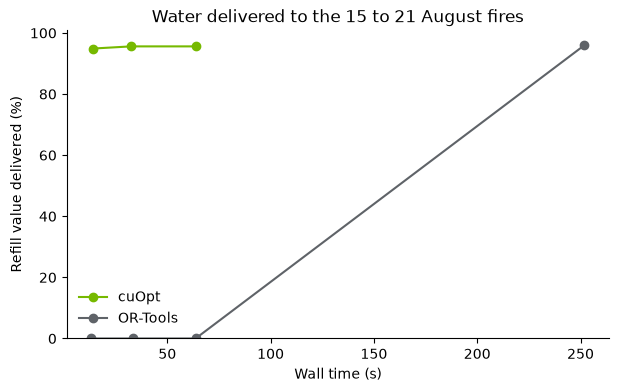

In [24]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, color in (("cuOpt", "#76b900"), ("OR-Tools", "#5f6368")):
    d = results[results.solver == name]
    ax.plot(
        d["wall time (s)"],
        d["value delivered (%)"],
        marker="o",
        color=color,
        label=name,
    )
ax.set_xlabel("Wall time (s)")
ax.set_ylabel("Refill value delivered (%)")
ax.set_title("Water delivered to the 15 to 21 August fires")
ax.set_ylim(bottom=0)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

Within 10 seconds, cuOpt has a plan that delivers about 95% of the refill value, and longer budgets change it by a point or so. cuOpt plans every tender and every refill together. A tender in its plan can carry refills for two fires in one load, and move on to wherever the next refill is due.

OR-Tools reaches about the same plan, but on this machine it needs a little over two minutes to produce its first one. Its search runs on one CPU core, so a faster CPU narrows the gap. On a laptop with faster cores (Apple M4 Pro), it found a plan in about 30 seconds. In our earlier tests on smaller and larger versions of this problem, the gap grew with the size of the problem. Every plan passes the same check, and cuOpt's search is randomized, so a rerun can differ by a point or two.

## Stage 5 · Look at the Results

### 1. Map the cuOpt Plan

The map starts with the fires, colored and sized by tier. Click a fire to see the trips tenders made to serve it. Arrows show the direction of travel, from wherever each tender was to the fill site and on to the fire. The plan knows every fire in advance, so some tenders set off before a fire is reported. The fire's fill site appears as a blue dot. The popup says when the fire appeared and when its engines arrived. It also lists when each tender handed over a refill, and how many of the fire's refills arrived on time. Click anywhere else on the map to clear the selection. The view stays on the area of interest, and the reset button under the zoom controls returns to the full area.

The trips follow real roads. The second `WaypointMatrix` kept the shortest paths between tenders, fill sites and fires, and `compute_waypoint_sequence` turns each trip back into the roads it drives.

In [25]:
best = plans["cuOpt", 60]
_, on_time = score(best, return_delivered=True)
on_time = set(on_time)

# Each trip is one leg between two locations.
# A leg belongs to a fire when it ends at a fill or a delivery for that fire.
legs, fire_legs, fire_drops = {}, {}, {}
for t, stops in best.items():
    at = t
    for kind, r, stamp in stops:
        if kind == "rest":
            continue
        loc = int(
            refills.pick_loc.values[r] if kind == "fill" else refills.drop_loc.values[r]
        )
        f = int(refills.fire.values[r])
        if locations[loc] != locations[at]:
            leg = legs.setdefault((at, loc), len(legs))
            fire_legs.setdefault(f, set()).add(leg)
        if kind == "drop" and r in on_time:
            fire_drops.setdefault(f, {}).setdefault(t, []).append(stamp)
        at = loc

# compute_waypoint_sequence returns one road path through every leg in turn. Between legs it also includes the
# drive from one leg's end to the next leg's start, so each leg's own path starts at the last visit to its start node.
rows = []
for (a, b), k in legs.items():
    rows += [
        {"truck_id": k, "location": a, "type": "Depot"},
        {"truck_id": k, "location": b, "type": "Delivery"},
    ]
waypoints = tender_paths.compute_waypoint_sequence(
    locations, cudf.DataFrame(rows)
).to_pandas()
seq, kinds = waypoints.waypoint_sequence.values, waypoints.waypoint_type.values
ends = np.where(kinds == "Delivery")[0]
assert len(ends) == len(legs)
paths, after = [], 0
for (a, _), k in legs.items():
    first = after + np.where(seq[after : ends[k] + 1] == locations[a])[0][-1]
    nodes = seq[first : ends[k] + 1]
    nodes = np.r_[nodes[:-1:25], nodes[-1]]  # every 25th road point keeps the map small
    paths.append([[round(node_lat[n], 4), round(node_lon[n], 4)] for n in nodes])
    after = ends[k] + 1

START = pd.Timestamp(DAYS[0])


def when(minutes, day):
    """Clock time of a minute offset from the start of the week, with the date when it isn't `day`."""
    t = START + pd.Timedelta(minutes=float(minutes))
    return t.strftime("%H:%M") if t.normalize() == day else t.strftime("%d %b %H:%M")


drafting = set(drafting_nodes.tolist())
colors = {"high": "#d93025", "medium": "#f29900", "low": "#fbbc04"}
fire_points = []
for f, row in enumerate(fires.itertuples()):
    day = (START + pd.Timedelta(minutes=float(row.appear))).normalize()
    engines = sorted(visits.arrive[visits.fire == f])
    lines = [
        f"{row.tier.title()} tier fire, recorded final size {row.FIRE_SIZE:,.{0 if row.FIRE_SIZE >= 1 else 2}f} acres",
        f"Appeared {when(row.appear, None)}",
        "Engines arrived " + ", ".join(when(m, day) for m in engines),
    ]
    needed = int((refills.fire == f).sum())
    site = None
    if needed:
        node = fill_site[f]
        site = [node_lat[node], node_lon[node]]
        drops = fire_drops.get(f, {})
        lines.append(
            "Fill site: "
            + (
                "drafting from open water"
                if node in drafting
                else "hydrant, tank or tower"
            )
        )
        lines.append(
            f"{sum(map(len, drops.values()))} of {needed} refills arrived on time"
        )
        for t, stamps in sorted(drops.items(), key=lambda x: min(x[1])):
            lines.append(
                f"Tender {t + 1}: " + ", ".join(when(m, day) for m in sorted(stamps))
            )
    else:
        lines.append("No refills needed")
    fire_points.append(
        {
            "lat": row.LATITUDE,
            "lon": row.LONGITUDE,
            "radius": {"high": 7, "medium": 5, "low": 3}[row.tier],
            "color": colors[row.tier],
            "legs": sorted(fire_legs.get(f, ())),
            "site": site,
            "text": "<br>".join(lines),
        }
    )


class FireTrips(JSCSSMixin, MacroElement):
    """Draws the fires. A click on a fire shows its fill site and the trips that served it."""

    # Leaflet.TextPath repeats an arrow along each trip to show the direction of travel
    default_js = [
        (
            "leaflet_textpath",
            "https://cdn.jsdelivr.net/npm/leaflet-textpath@1.2.3/leaflet.textpath.min.js",
        )
    ]
    # [[ ]] marks the template's placeholders, so the docs build's own templating leaves them alone
    _template = Template(
        """
    {% macro script(this, kwargs) %}
    (function () {
      var map = [[ this._parent.get_name() ]];
      var paths = [[ this.paths ]];
      var shown = L.layerGroup().addTo(map);
      var markers = [];
      // Keep the view on the area of interest: no panning outside it, no zooming out past it
      var area = L.latLngBounds([[ this.bounds ]]);
      map.fitBounds(area);
      map.setMaxBounds(area);
      map.options.maxBoundsViscosity = 1.0;
      map.setMinZoom(map.getBoundsZoom(area));
      var reset = L.control({position: "topleft"});
      reset.onAdd = function () {
        var bar = L.DomUtil.create("div", "leaflet-bar");
        var button = L.DomUtil.create("a", "", bar);
        button.href = "#";
        button.title = "Reset view";
        button.innerHTML = "&#8634;";
        L.DomEvent.on(button, "click", function (e) {
          L.DomEvent.stop(e);
          shown.clearLayers();
          map.closePopup();
          map.fitBounds(area);
        });
        return bar;
      };
      reset.addTo(map);
      [[ this.fires ]].forEach(function (f) {
        var marker = L.circleMarker([f.lat, f.lon],
                                    {radius: f.radius, color: f.color, fillColor: f.color, fillOpacity: 0.9, weight: 1})
          .bindPopup(f.text, {maxHeight: 220}).addTo(map)
          .on("click", function () {
            shown.clearLayers();
            f.legs.forEach(function (k) {
              // not clickable, so a click on a fire under a trip still reaches the fire
              L.polyline(paths[k], {color: "#188038", weight: 3, opacity: 0.85, interactive: false})
                .addTo(shown)
                .setText("    ►    ", {
                  repeat: true,
                  offset: 5,
                  attributes: {fill: "#188038", "font-size": "14", "pointer-events": "none"},
                });
            });
            markers.forEach(function (m) { m.bringToFront(); });  // draw the fires above the trips
            if (f.site) {  // added last, so the fill site stays visible even right next to the fire
              L.circleMarker(f.site, {radius: 6, color: "#ffffff", fillColor: "#1a73e8", fillOpacity: 1, weight: 2})
                .bindTooltip("Fill site").addTo(shown);
            }
          });
        markers.push(marker);
      });
      map.on("click", function () { shown.clearLayers(); });
    })();
    {% endmacro %}
    """,
        variable_start_string="[[",
        variable_end_string="]]",
    )

    def __init__(self, paths, fire_points, bounds):
        super().__init__()
        # default=float turns NumPy numbers into plain floats that JSON accepts
        self.paths, self.fires, self.bounds = (
            json.dumps(x, default=float) for x in (paths, fire_points, bounds)
        )


fmap = folium.Map(
    location=[fires.LATITUDE.mean(), fires.LONGITUDE.mean()], zoom_start=7
)
fmap.add_child(FireTrips(paths, fire_points, [[LAT0, LON0], [LAT1, LON1]]))
# At most 900 px wide, so the map stays readable on wide screens and still shrinks on narrow ones
frame = Figure(width="min(100%, 900px)")
frame.add_child(fmap)
frame

### 2. Compare the Planners

The fair comparison is how much value each planner delivers for the same time budget.

In [26]:
results.pivot(index="budget (s)", columns="solver", values="value delivered (%)")

solver,OR-Tools,cuOpt
budget (s),,
10,0.0,94.9
30,0.0,95.6
60,0.0,95.6
240,96.0,NaN


## Summary

We replayed a week of the August 2020 California lightning wildfires end to end on one GPU. We cleaned five years of fire records with cuDF and ranked the new fires with XGBoost. We built a road network from OpenStreetMap and sent engines by a closest-engine rule. Then cuOpt planned a week of water tender routes.

cuDF and XGBoost keep data preparation and training on the GPU. The heart of the workflow is the routing. cuOpt turned a week of fires into a plan that delivered about 95% of the refill value, weighted by tier, within 10 seconds. OR-Tools, solving the same problem on this machine's CPU, reached a plan of the same quality after a little over two minutes. When fires keep being reported, a good plan in seconds is what makes re-planning practical.

## Future Steps

Re-plan as fires are reported. The week is planned knowing every fire in advance. A real dispatcher re-plans whenever a fire is reported. That is exactly where a plan in 10 seconds matters most. cuOpt can start from the previous plan, so each re-plan only has to fit in the new fires.

Let tenders choose where to fill. Each fire has one designated fill site here. Letting a tender fill at any water on its way would cut driving, at the cost of a bigger problem.

Add more realism to the wildfire response. Here engines don't rest, and water use is the same at every fire. Everyone drives at car speeds. There are no aircraft, dozers or hand crews, and no help from outside the region.

### Resources

- [cuOpt documentation](https://docs.nvidia.com/cuopt/user-guide/latest/introduction.html) and [cuopt-examples](https://github.com/NVIDIA/cuopt-examples), including [last-mile delivery](https://github.com/NVIDIA/cuopt-examples/tree/main/last_mile_delivery)
- [FPA FOD-Attributes dataset](https://zenodo.org/records/8381129) (Pourmohamad et al., 2024, CC BY 4.0)
- Short, Karen C. 2022. Spatial wildfire occurrence data for the United States, 1992-2020 [FPA_FOD_20221014]. 6th Edition. Fort Collins, CO: Forest Service Research Data Archive. <https://doi.org/10.2737/RDS-2013-0009.6>
- [Geofabrik OpenStreetMap extracts](https://download.geofabrik.de/)
- [OR-Tools vehicle routing guide](https://developers.google.com/optimization/routing)